# 90 — Quatro contas AWS e suas fronteiras

Referência: [AgentCore workshops](https://github.com/awslabs/agentcore-samples/tree/main/06-workshops). Esta aula conserva o código da arquitetura anterior enquanto sua conversão está pendente.

**Bloco final multiconta — fora da jornada de conta única do Workshop Studio.** Anteriormente aula 10; o ID `10` nas chamadas e evidências legadas permanece estável. A mudança de ordem não altera os recursos nem dispensa as quatro contas.

## Arquitetura desta aula

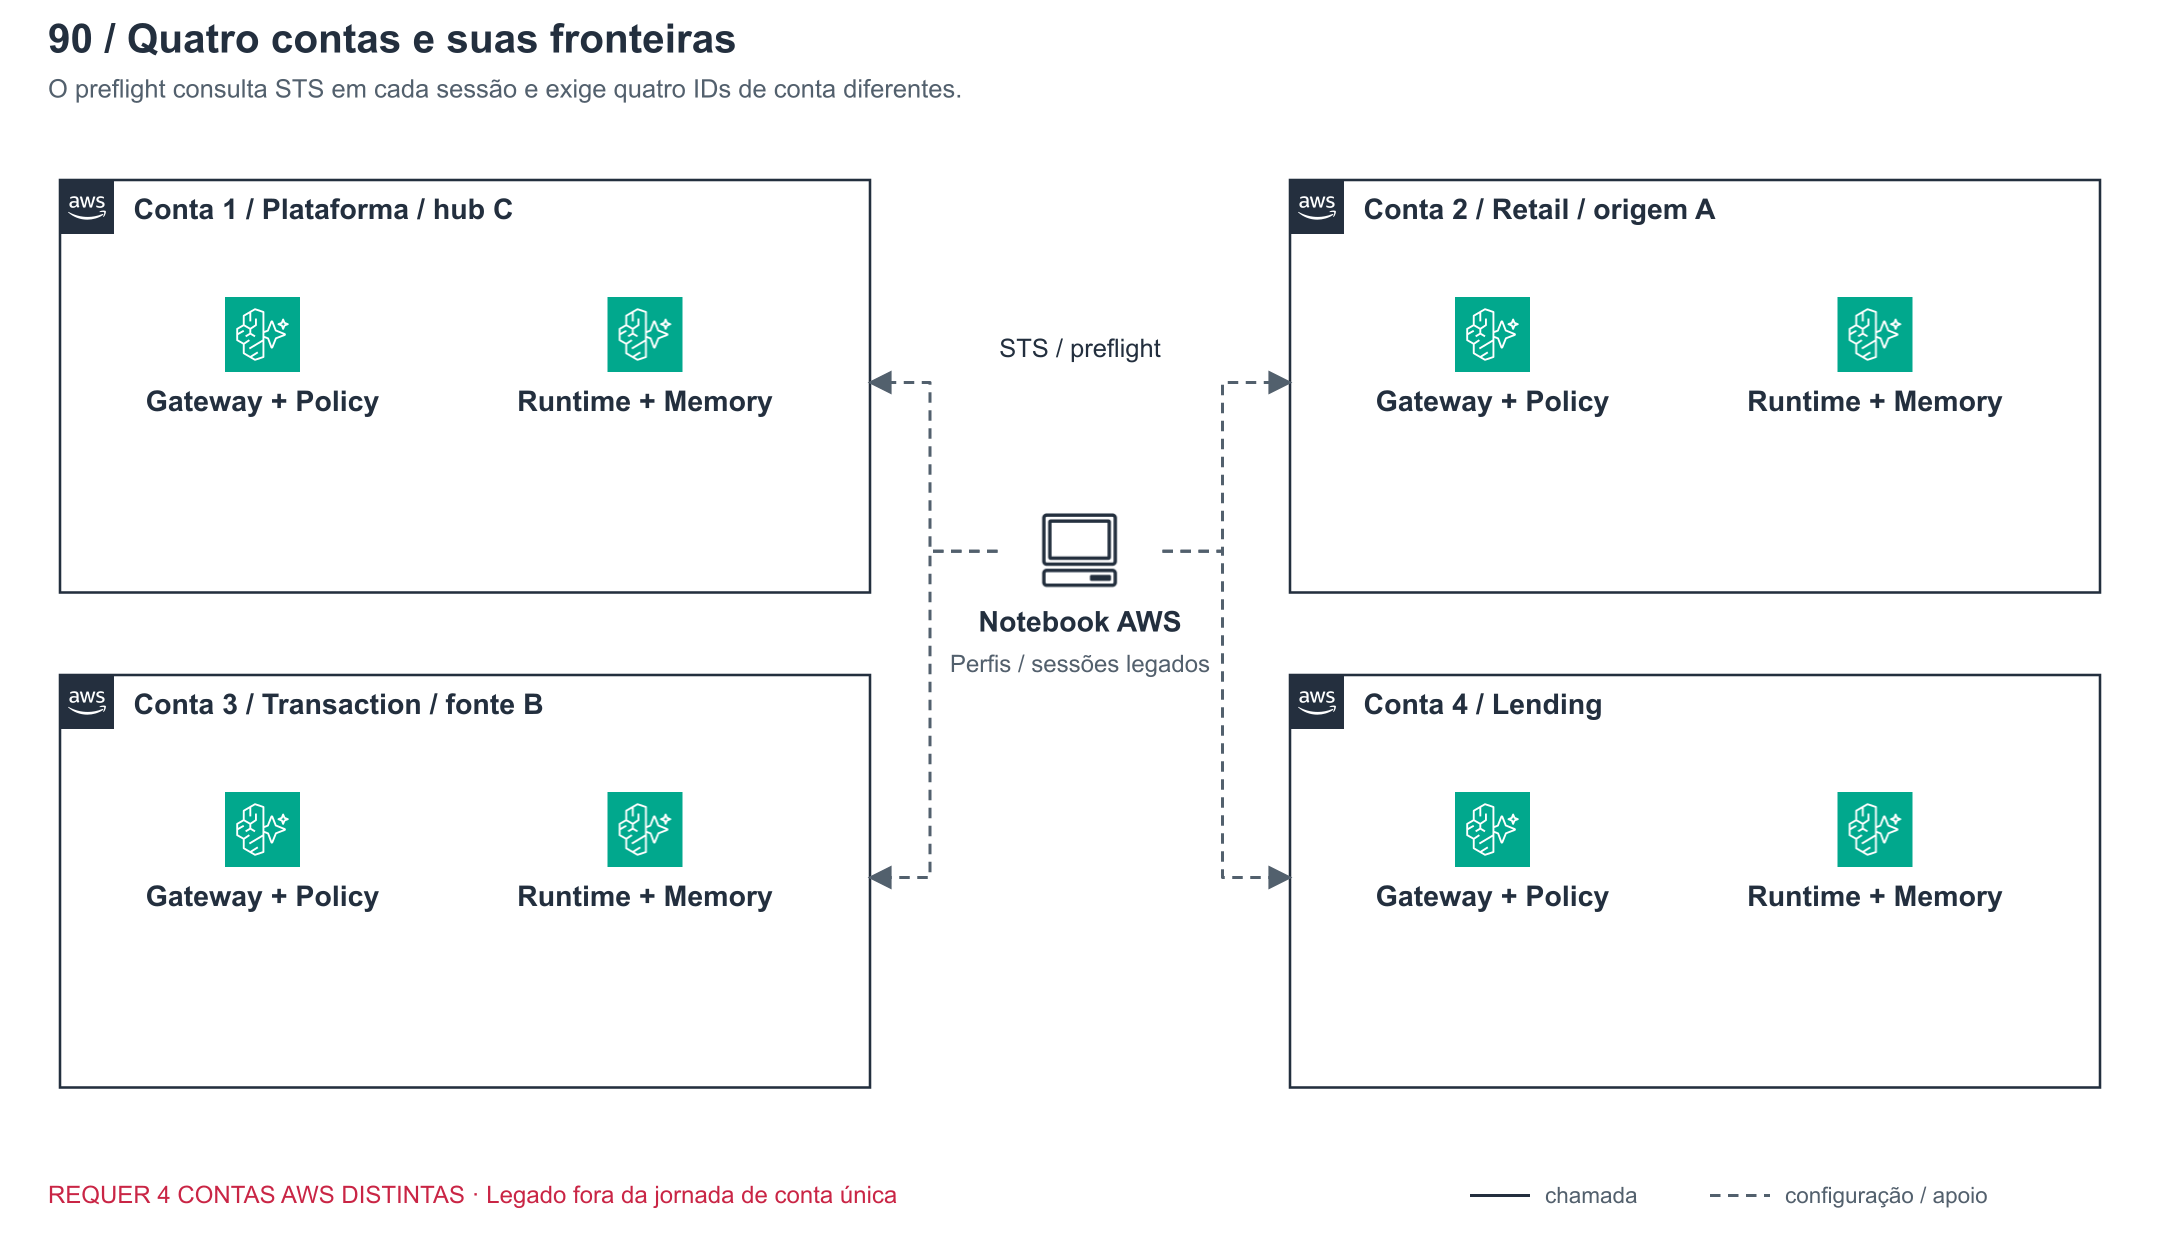

**Como ler o desenho:** Cada caixa externa é uma conta AWS diferente. A plataforma é o hub C, Retail é a origem A e Transaction é a fonte B. Lending é a quarta conta exigida pelo manifesto legado, mesmo sem participar de todos os fluxos.

[Abrir PNG](../docs/diagramas/aulas/90.png) · [Abrir SVG](../docs/diagramas/aulas/90.svg)

## O que você vai aprender

**Pergunta da aula:** Como verificar que uma arquitetura usa fronteiras reais entre contas AWS?

1. Identificar plataforma, Retail, Transaction e Lending.
2. Comparar IDs STS e disponibilidade dos ambientes de cada domínio.

**Estudo do legado — quatro contas AWS distintas.** Esta aula ainda depende da implantação anterior e não foi validada na jornada SDK atual. Não execute este notebook na conta única do Workshop Studio.

**Antes de começar:** Legado: quatro contas distintas, configuração e recursos da arquitetura anterior preparados.

**O que esta aula cria ou remove:** Nenhum recurso; as células inspecionam ambientes previamente implantados.

**O que reutiliza:** As quatro contas e a configuração do legado. Esta aula não usa apenas os recursos criados em 00–09.

## Serviços AWS e suas responsabilidades

| Serviço | O que ele faz | Papel nesta aula |
|---|---|---|
| **AWS Security Token Service (STS)** | Identifica o principal da sessão e emite credenciais temporárias ao assumir uma role. | Confirma IDs distintos, evitando confundir perfis diferentes com contas diferentes. |
| **AWS Identity and Access Management (IAM)** | Controla quais ações uma identidade pode executar em quais recursos. A trust policy define quem pode assumir uma role; a policy de permissões define seu acesso. | Controla as sessões entre contas e suas permissões. |
| **Amazon Bedrock AgentCore Gateway** | Expõe ferramentas por MCP, autentica chamadas e encaminha operações aos targets. O schema informa nome, argumentos e contrato de cada ferramenta. | Fornece uma entrada por domínio. |
| **Amazon Bedrock AgentCore Runtime** | Hospeda código de agentes ou servidores MCP com sessão, endpoint e role de execução. A identidade que invoca o endpoint é distinta da identidade usada pelo código hospedado. | Hospeda as capacidades em cada domínio. |
| **Amazon Bedrock AgentCore Policy** | Avalia regras Cedar sobre principal, ação, recurso e contexto de uma chamada. O engine associado ao Gateway em ENFORCE aplica suas decisões antes da ferramenta. | Mantém decisões por domínio. |
| **Amazon Bedrock AgentCore Memory** | Armazena eventos de interação associados a actor e sessão. Nesta aula usamos eventos com referências; não configuramos extração de memória de longo prazo. | Faz parte dos ambientes consultados pelo preflight legado. |

**Roteiro de execução:** leia a configuração e o código, execute a célula, aguarde o estado indicado e interprete a evidência antes de avançar. As seções **Validação** destacam chamadas e asserts já presentes na aula. Um erro inesperado não equivale a uma negativa autorizada esperada.

## Pré-requisito: 4 contas AWS distintas

**Esta aula não executa em uma conta única.** O fluxo mostrado envolve 4 contas (platform, retail-banking, transaction-banking, lending-wealth), mas o manifesto e o IaC atuais exigem as quatro contas preparadas: plataforma, Retail, Transaction e Lending. Sem elas, reserve a aula para demonstração do instrutor no ambiente completo ou retire-a da seleção de execução.

A jornada SDK atual de conta única inclui 00–09 e 15–16. Os recursos dessas aulas não preparam esta integração legada. Confira a [matriz de contas e execução](../docs/contas-e-elegibilidade.md).

Todos os serviços e agentes desta jornada são implantados na AWS.
O notebook é o roteiro e cliente das APIs; ferramentas, inferência,
políticas, fontes e memória executam nos serviços indicados.
Use o ambiente AWS descrito no [guia de implantação](../docs/deploy.md).
Configure os identificadores dos stacks antes de executar. Uma
dependência ausente bloqueia a aula antes das chamadas do exercício.
Antes de usar “Run All”, selecione as aulas compatíveis com as contas
preparadas. O bloco 10–14 exige quatro contas na implantação atual.

### Carregar a configuração e conferir as dependências

A configuração contém perfis/roles e IDs, nunca senhas ou tokens. O STS confirma a conta antes de consultar os stacks; o manifesto exige as dependências desta aula.

In [ ]:
import json
import os
import uuid
from pathlib import Path
from IPython.display import Code, display
import inspect
from santander_demo.aws_workshop.client import AWSWorkshop
from santander_demo.aws_workshop.config import load
from santander_demo.aws_workshop.manifest import require

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = Path(os.environ.get("WORKSHOP_CONFIG", ROOT / "config/aws.workshop.json"))
config = load(CONFIG)
dependencies = require(config, "10")
print({"lab": "10", "dependencies": list(dependencies), "region": config["region"]})

### Confirmar quatro contas reais

Os perfis do operador ou as roles do runner identificam as contas. IDs repetidos não são aceitos como cenário entre contas.

### Validação — quatro identidades de conta

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Sessões configuradas | Quatro account_id distintos | Perfis não estão apontando para a mesma conta. |

In [ ]:
from santander_demo.aws_workshop.config import DOMAINS, check_accounts
accounts = check_accounts(config, domains=DOMAINS)
assert len({x["account_id"] for x in accounts.values()}) == 4
print(json.dumps(accounts, indent=2))

### Leitura do resultado — quatro identidades de conta

Este assert só comprova a distinção das contas. O preflight seguinte consulta os recursos de cada domínio; quatro credenciais válidas não comprovam que os serviços foram implantados.

### Verificar Gateway, Runtime, Policy e Memory em cada domínio

Cada consulta usa a sessão da conta correspondente e o stack exato. Uma aplicação implantada só na plataforma não satisfaz esta verificação.

In [ ]:
environments = {}
for domain in DOMAINS:
    environments[domain] = AWSWorkshop(CONFIG, domain).preflight()
print(json.dumps(environments, indent=2))

**Mapa:** plataforma é o hub C; Retail é a origem A; Transaction é a fonte B; Lending é o terceiro domínio bancário. IAM/STS controlam administração e observação. Os Gateways validam a pessoa por JWT e aplicam suas próprias políticas.

### Evidências e encerramento

Registre IDs de requisição e decisões, sem tokens ou senhas. Os recursos são compartilhados entre aulas: a remoção pertence ao pipeline de limpeza do projeto e deve respeitar essa dependência.

## Análise dos resultados

A leitura permite discutir isolamento administrativo e limites de confiança entre contas.

**Evidência e alcance:** Esta aula continua **pendente de conversão e teste no ambiente atual**. Os resultados acima são critérios esperados do código legado, não uma nova evidência de execução.

**Limites da demonstração:** O fluxo executável permanece legado e não foi validado na atual jornada de conta única. Sem as quatro contas e a implantação anterior, use esta aula somente para estudo da arquitetura.

**Para discutir:** Dois perfis com o mesmo account_id demonstram uma integração entre contas?

**Registro da aula:** anote conta/região, run_id quando disponível, casos permitidos/negados e IDs de requisição. Preserve a mensagem de uma falha inesperada; não publique tokens, senhas ou credenciais nas saídas. Os notebooks do repositório são distribuídos sem outputs.